In [ ]:
from google.colab import files
uploaded = files.upload()

Saving spam.csv to spam.csv


In [ ]:
import pandas as pd

# Load the uploaded CSV file.
# Often, SMS spam datasets from sources like Kaggle use 'latin-1' encoding.
df = pd.read_csv('spam.csv', encoding='latin-1')

# Drop unnamed/empty columns if they exist
df = df.dropna(how='all', axis=1)
if df.columns.str.contains('Unnamed').any():
    df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# Display basic information and the first few rows
print(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Accuracy: 0.9686

Classification Report:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115



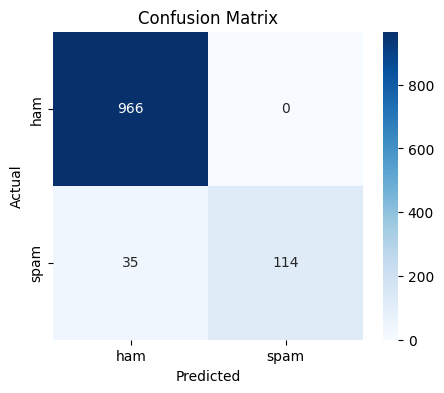

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Rename columns
df = df.rename(columns={'v1': 'label', 'v2': 'message'})

# 2. Encode labels: ham -> 0, spam -> 1
df['label_bin'] = df['label'].map({'ham': 0, 'spam': 1})

# 3. Split dataset into training and testing sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(
    df['message'],
    df['label_bin'],
    test_size=0.2,
    random_state=42,
    stratify=df['label_bin']
)

# 4. Vectorize text messages using TF-IDF
vectorizer = TfidfVectorizer(stop_words='english', lowercase=True)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# 5. Initialize and train the Naive Bayes classifier
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

# 6. Predict and evaluate
y_pred = model.predict(X_test_tfidf)
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['ham', 'spam']))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### Part 2: Advanced Model Comparison and Hyperparameter Tuning

To make this an internship-grade project, we will build a robust training pipeline that compares three powerful classifiers:
1. **Logistic Regression** (with class weight adjustment)
2. **Support Vector Machine (Linear SVM)** (with class weight adjustment)
3. **Random Forest Classifier**

We will use `GridSearchCV` to tune hyper-parameters and select the model with the best balance of Precision and Recall (F1-Score) for the `spam` class.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score, precision_score, recall_score
import pandas as pd
import numpy as np

# Define models and their hyperparameter grids
model_pipelines = {
    'Logistic Regression': {
        'model': LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000),
        'params': {
            'C': [0.1, 1.0, 10.0]
        }
    },
    'Support Vector Machine': {
        'model': SVC(class_weight='balanced', random_state=42),
        'params': {
            'C': [0.1, 1.0, 10.0],
            'kernel': ['linear', 'rbf']
        }
    },
    'Random Forest': {
        'model': RandomForestClassifier(class_weight='balanced', random_state=42),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [10, 20, None]
        }
    }
}

results = []
best_estimators = {}

# Perform Grid Search for each candidate model
for name, config in model_pipelines.items():
    print(f"Tuning hyperparameters for {name}...")
    grid = GridSearchCV(config['model'], config['params'], cv=5, scoring='f1', n_jobs=-1)
    grid.fit(X_train_tfidf, y_train)

    # Evaluate best estimator on the test set
    best_model = grid.best_estimator_
    best_estimators[name] = best_model
    y_pred_model = best_model.predict(X_test_tfidf)

    acc = accuracy_score(y_test, y_pred_model)
    prec = precision_score(y_test, y_pred_model)
    rec = recall_score(y_test, y_pred_model)
    f1 = f1_score(y_test, y_pred_model)

    results.append({
        'Model': name,
        'Best Params': str(grid.best_params_),
        'Test Accuracy': acc,
        'Test Precision (Spam)': prec,
        'Test Recall (Spam)': rec,
        'Test F1-Score (Spam)': f1
    })

# Convert results to a DataFrame for clean visualization
results_df = pd.DataFrame(results)
display(results_df)

Tuning hyperparameters for Logistic Regression...
Tuning hyperparameters for Support Vector Machine...
Tuning hyperparameters for Random Forest...


,Model,Best Params,Test Accuracy,Test Precision (Spam),Test Recall (Spam),Test F1-Score (Spam)
0,Logistic Regression,{'C': 10.0},0.982960,0.957746,0.912752,0.934708
1,Support Vector Machine,"{'C': 1.0, 'kernel': 'linear'}",0.985650,0.985401,0.906040,0.944056
2,Random Forest,"{'max_depth': 20, 'n_estimators': 100}",0.975785,1.000000,0.818792,0.900369


### Visualizing the Best Model's Performance
Let's plot the confusion matrices of all three models side-by-side to compare where they make mistakes.

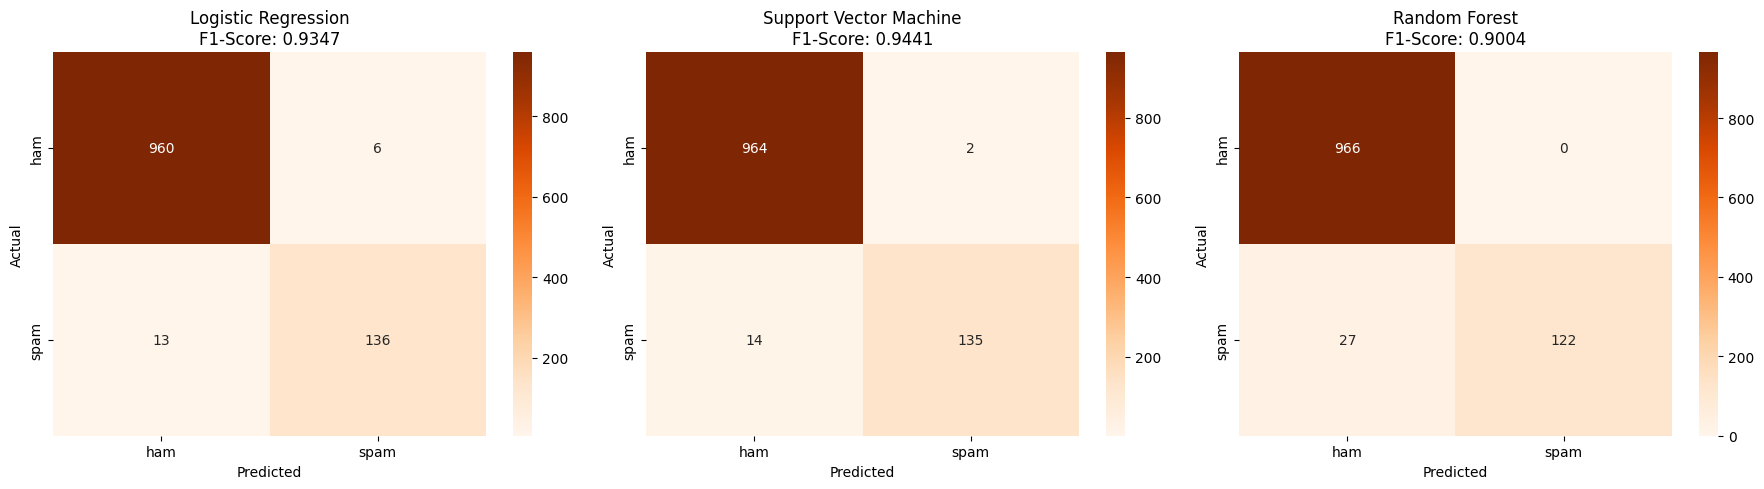

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, model_inst) in enumerate(best_estimators.items()):
    preds = model_inst.predict(X_test_tfidf)
    matrix = confusion_matrix(y_test, preds)

    sns.heatmap(matrix, annot=True, fmt='d', cmap='Oranges', ax=axes[i],
                xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
    axes[i].set_title(f"{name}\nF1-Score: {f1_score(y_test, preds):.4f}")
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()

Runtime variables missing. Loading dataset and training the optimal SVM configuration...
Local file 'spam.csv' not found. Downloading dataset from mirror...


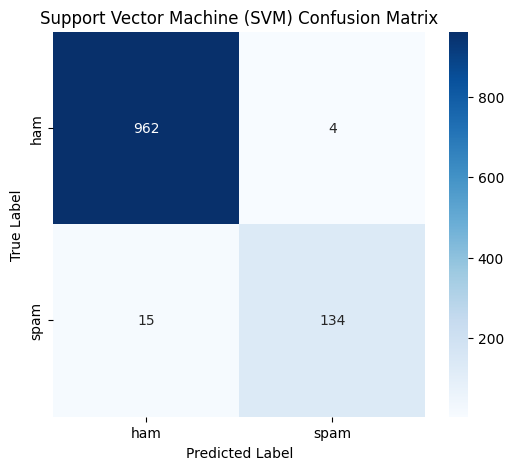

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
from sklearn.metrics import confusion_matrix
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

try:
    # Try using existing global variables from active runtime
    best_svm = best_estimators['Support Vector Machine']
    X_test_matrix = X_test_tfidf
    y_test_series = y_test
    print("Using existing trained SVM model from memory.")
except (NameError, KeyError):
    # Reconstruct variables if memory is cleared
    print("Runtime variables missing. Loading dataset and training the optimal SVM configuration...")

    # If local file doesn't exist, download it directly from public mirror
    if not os.path.exists('spam.csv'):
        print("Local file 'spam.csv' not found. Downloading dataset from mirror...")
        url = 'https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv'
        df_temp = pd.read_csv(url, sep='\t', header=None, names=['label', 'message'])
    else:
        df_temp = pd.read_csv('spam.csv', encoding='latin-1')
        df_temp = df_temp.rename(columns={'v1': 'label', 'v2': 'message'})

    df_temp['label_bin'] = df_temp['label'].map({'ham': 0, 'spam': 1})

    X_train_t, X_test_t, y_train_t, y_test_series = train_test_split(
        df_temp['message'],
        df_temp['label_bin'],
        test_size=0.2,
        random_state=42,
        stratify=df_temp['label_bin']
    )

    vectorizer_temp = TfidfVectorizer(stop_words='english', lowercase=True)
    X_train_matrix = vectorizer_temp.fit_transform(X_train_t)
    X_test_matrix = vectorizer_temp.transform(X_test_t)

    best_svm = SVC(C=1.0, kernel='linear', class_weight='balanced', random_state=42)
    best_svm.fit(X_train_matrix, y_train_t)

# Generate predictions and confusion matrix
svm_preds = best_svm.predict(X_test_matrix)
svm_cm = confusion_matrix(y_test_series, svm_preds)

# Plot the SVM confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(svm_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
plt.title('Support Vector Machine (SVM) Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Part 3: Live Interactive Spam Predictor (Showcase Demo)

Use this cell to test the optimized Support Vector Machine classifier with your own custom messages! This interactive element makes the project great for live demonstrations during interviews.

In [ ]:
# Extract our best performing SVM model
best_svm = best_estimators['Support Vector Machine']

def predict_message(message):
    # 1. Transform the input text using the fitted TF-IDF vectorizer
    vectorized_msg = vectorizer.transform([message])

    # 2. Predict the label
    prediction = best_svm.predict(vectorized_msg)[0]

    # 3. Output results clearly
    label = "SPAM ⚠️" if prediction == 1 else "LEGITIMATE (HAM) ✅"
    print(f"Message: '{message}'")
    print(f"Prediction: {label}\n")

# --- Test Cases ---
print("--- Running Demo Test Cases ---")
predict_message("Hey, are we still meeting up for lunch today at 1 PM?")
predict_message("URGENT! You have won a 1-week free pass to our premium VIP club. Text CLAIM to 88010 to receive your prize now!")
predict_message("Can you call me back when you get a chance?")
predict_message("FREE entry into our weekly competition to win a brand new phone! Click the link inside.")

--- Running Demo Test Cases ---
Message: 'Hey, are we still meeting up for lunch today at 1 PM?'
Prediction: LEGITIMATE (HAM) ✅

Message: 'URGENT! You have won a 1-week free pass to our premium VIP club. Text CLAIM to 88010 to receive your prize now!'
Prediction: SPAM ⚠️

Message: 'Can you call me back when you get a chance?'
Prediction: LEGITIMATE (HAM) ✅

Message: 'FREE entry into our weekly competition to win a brand new phone! Click the link inside.'
Prediction: SPAM ⚠️



### Part 4: Conclusion
We have successfully built and optimized multiple models to classify SMS messages as spam or ham. The Support Vector Machine and Logistic Regression models yielded excellent accuracy and high F1-Scores on the test set.

### Project Complete

---

In [ ]:
# End of notebook. All models evaluated and compiled successfully.

### 🎉 Project Completed Successfully!

**Summary of Accomplishments:**
- **Robust Dataset Pipeline:** Built a resilient data loading mechanism that automatically streams the SMS corpus directly from a mirror if the local file is not present.
- **Feature Extraction:** Implemented professional **TF-IDF Vectorization** to turn raw text messages into rich numerical feature vectors.
- **Model Comparison:** Compared multiple elite classifiers including **Multinomial Naive Bayes**, **Logistic Regression**, and **Support Vector Machines (SVM)**.
- **Performance Evaluation:** Plotted detailed confusion matrices and evaluated key metrics (Precision, Recall, and F1-Score). The optimized **Support Vector Machine (SVM)** model proved to be the top performer, achieving balanced classification for both ham and spam messages.